# Ad Click-Through Rate Prediction - In-Depth EDA (Notebook 01 of 3)

**Project.** CTR prediction on the Criteo Display Advertising Challenge dataset - a
public, anonymised benchmark from display advertising - built as an independent
portfolio project. Everything here runs on openly available data; nothing describes
or depends on any specific publisher's production systems.

**The three notebooks.**
1. `01_ctr_in_depth_eda.ipynb` (this one) - structure, integrity, class imbalance,
   missing values, numeric and categorical behaviour, interactions, leakage-safe
   splitting, train/validation comparison, SQL cross-checks, decision table.
2. `02_ctr_model_training.ipynb` - constant baseline, logistic regression, gradient
   boosted trees and DeepFM trained on the same split.
3. `03_ctr_model_evaluation.ipynb` - held-out evaluation: log loss (primary), ROC-AUC,
   PR-AUC, calibration, latency, missing/unseen-input behaviour.

**Business context in one paragraph.** An *impression* is one ad served; a *click* is a
user action on it; CTR = clicks / impressions. Ad-supported publishers use click
predictions to rank candidate ads for each impression, to price inventory and to decide
when not to show an ad. CTR is **not** conversions and **not** revenue: a click can
bounce, a conversion can happen without a click, and revenue depends on bids,
viewability and attribution windows. A 1% better predicted CTR does not mean 1% more
revenue - later notebooks keep that gap explicit.

**Section map** (spec section -> this notebook): sampling -> *S*; structure/integrity
-> *A*; leakage-aware partitions -> *G*; class imbalance -> *B*; missing values -> *C*;
numeric -> *D*; categorical -> *E*; interactions -> *F*; train-vs-val -> *H*; SQL
cross-checks -> later section; conclusions -> *I*.

**How to run.** From the project root:

```bash
python scripts/download_data.py   # fetch the raw pool once (~209 MB) if missing
make eda                          # builds + executes this notebook in place
```

All configuration (sample size, seed, split ratios, transform thresholds) lives in
`config.yaml`. Every output in this file was produced by executing the notebook
end-to-end from top to bottom.

In [1]:
import json
import sys
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

T_START = time.time()

# Project bootstrap: find the root (folder containing config.yaml) from the CWD.
_here = Path.cwd()
PROJECT_ROOT = next(p for p in [_here, *_here.parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import seaborn as sns

from ctr import data as ctr_data
from ctr import eda as ctr_eda
from ctr import sql_runner
from ctr.config import data_file, load_config

sns.set_theme(style="whitegrid", rc={"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9})

cfg = load_config()
SEED = int(cfg["seed"])
NUM_COLS = list(cfg["features"]["numeric_cols"])
CAT_COLS = list(cfg["features"]["categorical_cols"])
FEATURE_COLS = NUM_COLS + CAT_COLS

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=110, bbox_inches="tight")
    return path


def ctr_row(y):
    n = len(y)
    clicks = int(np.asarray(y).sum())
    lo, hi = ctr_eda.wilson_ci(clicks, n)
    return {"n": n, "clicks": clicks, "ctr": clicks / n, "ci_low": lo, "ci_high": hi,
            "ci_95_pct": "[{:.2f}%, {:.2f}%]".format(100 * lo, 100 * hi)}


pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 80)

print("project root:", PROJECT_ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__)

raw_path = data_file(cfg, "raw_path")
sample_path = data_file(cfg, "sample_path")
splits_dir = data_file(cfg, "splits_dir")
if not raw_path.exists():
    raise FileNotFoundError(
        "raw data not found at " + str(raw_path) + "\n"
        "Run:  python scripts/download_data.py   (then re-run this notebook)."
    )

project root: C:\Users\hp\Documents\Qoder\2026-10-14\55aa046d\ad-ctr-prediction-deepfm
pandas 3.0.6 | numpy 2.4.6


## S. Sampling - how the development dataset was built

**Q:** Which data exactly do we analyse, and how was this sample drawn?
**Why it matters:** every later number (CTR, missingness, split sizes) is conditioned
on this choice. If the sample is not a fair draw from the pool, all downstream
statistics inherit the bias.

**The raw pool.** `data/raw/criteo_pool.parquet` is a community mirror of the Criteo
Display Advertising Challenge *training* data (the original distribution is a
tab-separated file with no header; 45,840,617 labelled impressions in total). The
mirror file used here is a 4,584,062-row partition of that data, already converted to
parquet. Schema as verified in section A: `Label` (0/1), `I1`-`I13` (anonymised
numeric features, with missing entries) and `C1`-`C26` (8-character hex hashes of
anonymised categorical features). Two provenance caveats we carry through the whole
project:

1. the mirror's own split construction is unverified, and
2. there is **no timestamp column**, so real traffic order cannot be reconstructed.

We therefore treat rows as exchangeable draws and never claim temporal validity.

**Sampling method.** Simple random sample *without replacement* over row positions:
`numpy.random.default_rng(42).choice(total_rows, size=sample_rows, replace=False)`.
The parquet file is streamed in 131,072-row batches and only the selected positions
are materialised, so the full table never sits in memory. `sample_rows` (100,000 by
default) and the seed are configuration values - to scale up, set
`data.sample_rows` in `config.yaml` (for example 1000000, or `null` for all rows) and
rebuild.

In [2]:
t0 = time.time()
pool_rows = ctr_data.row_count(raw_path)
if sample_path.exists():
    sample = pd.read_parquet(sample_path)
    origin = "loaded cached sample"
else:
    sample = ctr_data.uniform_sample(
        raw_path, n=int(cfg["data"]["sample_rows"]), seed=SEED, batch_rows=int(cfg["data"]["batch_rows"])
    )
    sample_path.parent.mkdir(parents=True, exist_ok=True)
    sample.to_parquet(sample_path, index=False)
    origin = "drew fresh sample"
sample = ctr_data.normalize(sample)
print("{origin}: {n:,} of {pool:,} pool rows in {secs:.1f}s (seed={seed})".format(
    origin=origin, n=len(sample), pool=pool_rows, secs=time.time() - t0, seed=SEED))
print("sample file:", sample_path)

# Pool-level facts, computed with the same SQL files that are later reused on the
# sample: DuckDB queries the parquet directly, no Python loop.
con_pool = sql_runner.connect(raw_path)
pool_overview = sql_runner.run_file(con_pool, PROJECT_ROOT / "sql" / "01_overview.sql")
pool_missing = sql_runner.run_file(con_pool, PROJECT_ROOT / "sql" / "02_missing_values.sql")
print()
print(pool_overview.to_string(index=False))

# Representativeness: sample vs pool CTR (Wilson interval) and missingness.
samp_ctr = ctr_row(sample["label"])
print("pool CTR {p:.5f} | sample CTR {s:.5f} {ci}".format(
    p=pool_overview["ctr"][0], s=samp_ctr["ctr"], ci=samp_ctr["ci_95_pct"]))

pool_null_pct = 100 * pool_missing["n_missing"] / pool_rows
samp_null_pct = 100 * sample.isna().mean().reindex(pool_missing["feature"]).values
rep = pd.DataFrame({
    "feature": pool_missing["feature"],
    "pool_missing_pct": pool_null_pct.round(3),
    "sample_missing_pct": samp_null_pct.round(3),
})
rep["abs_diff_pp"] = (rep["pool_missing_pct"] - rep["sample_missing_pct"]).abs().round(3)
rep = rep[rep["pool_missing_pct"] > 0].sort_values("abs_diff_pp", ascending=False)
print("columns with missingness: {n}; largest sample-vs-pool gap: {g:.3f} pp".format(
    n=len(rep), g=rep["abs_diff_pp"].max()))
print(rep.head(8).to_string(index=False))

assert abs(samp_ctr["ctr"] - float(pool_overview["ctr"][0])) < 0.006, "sample CTR far outside 4-sigma of the pool"
assert rep["abs_diff_pp"].max() < 0.6, "sample missingness differs from the pool beyond sampling noise"

loaded cached sample: 100,000 of 4,584,062 pool rows in 0.2s (seed=42)
sample file: C:\Users\hp\Documents\Qoder\2026-10-14\55aa046d\ad-ctr-prediction-deepfm\data\processed\sample_dev.parquet



 impressions    clicks      ctr
     4584062 1174544.0 0.256223
pool CTR 0.25622 | sample CTR 0.25681 [25.41%, 25.95%]
columns with missingness: 24; largest sample-vs-pool gap: 0.241 pp
feature  pool_missing_pct  sample_missing_pct  abs_diff_pp
     I6            22.340              22.581        0.241
     C6            12.081              11.955        0.126
     I4            21.677              21.553        0.124
    I13            21.677              21.553        0.124
     I3            21.466              21.586        0.120
    I12            76.513              76.414        0.099
    C22            76.256              76.170        0.086
     I7             4.318               4.360        0.042


**What we see.** The sample CTR sits well inside +-4 standard errors of the pool CTR and
every missingness share is within a fraction of a percentage point of its pool value -
consistent with a fair uniform draw (subject to the mirror caveat above). The sampling
cost is seconds for 100,000 rows because only selected positions are materialised.

**Implication.** We proceed with the 100,000-row development sample. Every later
statistic is computed on its train/validation/test splits; scaling to 1M rows is a
config change plus a data rebuild, not a code change.

## A. Structure and integrity

**Q:** Does the file match the documented schema, and what state is it in?
**Why it matters:** model code written against the wrong schema, or an ill-defined
label, silently produces nonsense metrics. These checks run before any analysis.

Checks: column set and dtypes, label domain and missingness, memory footprint, full-row
duplicates (reported, deliberately **not** deleted - see below), and constant or
near-constant columns.

In [3]:
schema = ctr_data.validate_schema(sample)
print("validate_schema:", json.dumps(schema, indent=2))
print()

struct = pd.DataFrame({
    "dtype": sample.dtypes.astype(str),
    "n_missing": sample.isna().sum(),
    "pct_missing": (100 * sample.isna().mean()).round(3),
})
struct["role"] = ["label" if c == "label" else ("numeric" if c in NUM_COLS else "categorical")
                  for c in struct.index]
print(struct.groupby(["role", "dtype"], as_index=False).agg(
    columns=("dtype", "size"), total_missing=("n_missing", "sum")).to_string(index=False))

mem_bytes = int(sample.memory_usage(deep=True).sum())
print()
print("sample memory (deep): {mb:.1f} MB for {r:,} rows x {c} columns".format(
    mb=mem_bytes / 1e6, r=len(sample), c=sample.shape[1]))

label_counts = sample["label"].value_counts().sort_index()
print("label domain:", list(label_counts.index), "| counts:", label_counts.to_dict())
print()

dups_incl_label = int(sample.duplicated().sum())
h_feat = pd.util.hash_pandas_object(sample[FEATURE_COLS], index=False)
feat_dup_rows = int(h_feat.duplicated().sum())
grp = pd.DataFrame({"h": h_feat, "label": sample["label"].to_numpy()}).groupby("h")["label"]
mixed_labels = int((grp.nunique() > 1).sum())
print("full-row duplicates (features + label identical): {:,} rows ({:.3f}%)".format(
    dups_incl_label, 100 * dups_incl_label / len(sample)))
print("rows sharing an identical feature vector (64-bit hash, collisions negligible): {:,} ({:.3f}%)".format(
    feat_dup_rows, 100 * feat_dup_rows / len(sample)))
print("feature-identical groups whose labels disagree: {:,}".format(mixed_labels))
print("duplicates are REPORTED, not deleted (see interpretation below)")

nc = ctr_eda.near_constant_report(sample, FEATURE_COLS, threshold=0.995)
print()
print("near-constant columns (top value >= 99.5% of rows): {}".format(len(nc)))
print(nc.to_string(index=False) if len(nc) else "none")

validate_schema: {
  "n_rows": 100000,
  "n_columns": 40,
  "unexpected_columns": [],
  "label_values": [
    0,
    1
  ],
  "numeric_columns_not_numeric_dtype": [],
  "categorical_dtypes": [
    "str"
  ]
}

       role   dtype  columns  total_missing
categorical     str       26         284453
      label   int64        1              0
    numeric float64       12         270198
    numeric   int64        1              0

sample memory (deep): 50.7 MB for 100,000 rows x 40 columns
label domain: [0, 1] | counts: {0: 74319, 1: 25681}



full-row duplicates (features + label identical): 0 rows (0.000%)
rows sharing an identical feature vector (64-bit hash, collisions negligible): 0 (0.000%)
feature-identical groups whose labels disagree: 0
duplicates are REPORTED, not deleted (see interpretation below)



near-constant columns (top value >= 99.5% of rows): 0
none


**What we see.** The file matches the documented Criteo schema exactly: one 0/1 label
without gaps, 13 numeric columns (12 float64 for the columns with gaps, 1 int64), 26
string columns, no unexpected columns. The 100k-row sample fits in about 51 MB. And the
duplicate check comes back empty: **no** full-row duplicates and **no** repeated feature
vectors at all. That is itself informative - across 39 mostly high-entropy anonymous
features, fingerprints essentially never collide at this scale, so there is nothing to
deduplicate and no duplicated-label confusion to resolve.

**Decisions.**
- Duplicate policy: reported, never auto-deleted. Here the question is moot (zero
  repeats); had repeats existed they would have been kept - repeated contexts are
  legitimate traffic - with cross-partition overlap quantified in section G.
- **No near-constant column was silently dropped.** If any column were effectively
  constant it would be harmless anyway (trees ignore it, L2 shrinks it); removing
  features is a modelling decision that belongs to validation, not to cleaning.

## G. Partitions and leakage-safe design

*(Placed before all target-driven analysis on purpose: the partitions must exist before
the label is allowed to influence anything.)*

**Q:** How do we partition the data, and how do we stop the label from leaking?
**Why it matters:** the classic CTR modelling failures are leakage failures - target
encoding computed over all rows, imputation or scaling fitted on everything, features
chosen after peeking at the test set. Leakage inflates offline metrics and the damage
in production is worse than a bad report: an auction model scored on rows whose labels
it has already seen bids for the wrong inventory.

**Split design (given that no timestamps exist).**

- 70 / 15 / 15 train / validation / test, stratified on the label, seed 42 - reproducible
  and label-balanced by construction.
- Roles: **train** fits everything, including every statistic (medians, means,
  vocabularies); **validation** is for model choice, early stopping and any threshold
  tuning; **test** is locked away until notebook 03.
- A time-based split would be more realistic for advertising (tomorrow's traffic is not
  yesterday's), but there is no timestamp column and inventing an order would be
  fabrication. This is a stated limitation: a random split measures generalisation to
  *exchangeable* traffic, not to future traffic.

**Rules enforced downstream** (implemented in `src/ctr/features.py`, demonstrated in the
cells below):

1. every fitted statistic is computed on the train split only and frozen before
   val/test are transformed;
2. no target encoding anywhere in the pipeline (the demo below shows why);
3. the test split is only ever transformed and scored - never used to pick features,
   tune models or fit statistics.

In [4]:
manifest_path = splits_dir / "split_manifest.json"
if manifest_path.exists():
    splits = ctr_data.load_splits(splits_dir)
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    print("loaded existing splits from", splits_dir)
else:
    splits = ctr_data.stratified_split(sample, ratios=cfg["data"]["split"], seed=SEED)
    manifest = {
        "seed": SEED,
        "ratios": cfg["data"]["split"],
        "method": "stratified on label; per-class seeded permutation of row positions",
        "source": str(sample_path),
        "rows_in_sample": int(len(sample)),
    }
    ctr_data.save_splits(splits, splits_dir, manifest)
    print("created splits in", splits_dir)
train, val, test = splits["train"], splits["val"], splits["test"]

split_summary = pd.DataFrame({name: ctr_row(part["label"]) for name, part in splits.items()}).T
split_summary["ci_95_pct"] = split_summary["ci_95_pct"]
print(split_summary.to_string())
print("total rows:", sum(len(p) for p in splits.values()), "| sample rows:", len(sample))

assert sum(len(p) for p in splits.values()) == len(sample)
ctrs = [split_summary.loc[name, "ctr"] for name in ("train", "val", "test")]
assert max(ctrs) - min(ctrs) < 0.01, "stratification failed: base rates differ across partitions"
manifest

loaded existing splits from C:\Users\hp\Documents\Qoder\2026-10-14\55aa046d\ad-ctr-prediction-deepfm\data\processed\splits
           n clicks       ctr    ci_low   ci_high         ci_95_pct
train  69999  17976  0.256804  0.253581  0.260053  [25.36%, 26.01%]
val    14999   3852  0.256817  0.249888  0.263871  [24.99%, 26.39%]
test   15002   3853  0.256832  0.249904  0.263885  [24.99%, 26.39%]
total rows: 100000 | sample rows: 100000


{'seed': 42,
 'sample_rows': 100000,
 'splits': {'train': {'rows': 69999, 'ctr': 0.25680366862383747},
  'val': {'rows': 14999, 'ctr': 0.2568171211414094},
  'test': {'rows': 15002, 'ctr': 0.2568324223436875}}}

### G.1 Why target encoding is banned here (with numbers)

A common way to feed a high-cardinality category into a model is to replace it with the
average CTR of that category. Computed over the rows you train on, each row's encoding
contains its own label - which is exactly what the model is asked to predict. The cells
below quantify the inflation on `C1` and then check a second leakage surface: identical
feature vectors appearing on both sides of a partition boundary.

In [5]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

col = "C1"
prior = float(train["label"].mean())

# (a) in-sample: encode each row with CTRs computed on the whole train split,
#     including the row's own label - the classic leak.
enc_insample = train.groupby(col)["label"].transform("mean")
auc_insample = roc_auc_score(train["label"], enc_insample)

# (b) out-of-fold: each row encoded from the other four folds only.
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
enc_oof = pd.Series(np.nan, index=train.index)
for fit_idx, apply_idx in kf.split(train):
    stats = train.iloc[fit_idx].groupby(col)["label"].mean()
    enc_oof.loc[train.index[apply_idx]] = train.iloc[apply_idx][col].map(stats).to_numpy()
enc_oof = enc_oof.fillna(prior)
auc_oof = roc_auc_score(train["label"], enc_oof)

# (d) honest: train-only statistics applied to validation rows.
enc_val_honest = val[col].map(train.groupby(col)["label"].mean()).fillna(prior)
auc_val_honest = roc_auc_score(val["label"], enc_val_honest)

# (c) full-data statistics (train+val+test) applied to validation rows: val labels leak in.
full_stats = sample.groupby(col)["label"].mean()
enc_val_full = val[col].map(full_stats).fillna(sample["label"].mean())
auc_val_full = roc_auc_score(val["label"], enc_val_full)

demo1 = pd.DataFrame({
    "encoding_of_C1": ["train rows, in-sample stats (a)", "train rows, out-of-fold stats (b)",
                       "val rows, train-only stats (d)", "val rows, full-data stats (c)"],
    "scored_on": ["train", "train", "val", "val"],
    "auc": np.round([auc_insample, auc_oof, auc_val_honest, auc_val_full], 4),
})
print(demo1.to_string(index=False))

support = train[col].value_counts()
print()
print("{c} levels in train: {n:,}; levels with support <= 2 (one row's label becomes the encoding): {rare:,}".format(
    c=col, n=int(support.size), rare=int((support <= 2).sum())))
assert auc_insample > auc_oof, "expected in-sample encoding to look stronger than out-of-fold"

                   encoding_of_C1 scored_on    auc
  train rows, in-sample stats (a)     train 0.5194
train rows, out-of-fold stats (b)     train 0.5004
   val rows, train-only stats (d)       val 0.4968
    val rows, full-data stats (c)       val 0.5170

C1 levels in train: 443; levels with support <= 2 (one row's label becomes the encoding): 274


In [6]:
# Second leakage surface: identical feature vectors across partitions.
train_hash = pd.Index(pd.util.hash_pandas_object(train[FEATURE_COLS], index=False))
val_hash = pd.Index(pd.util.hash_pandas_object(val[FEATURE_COLS], index=False))
test_hash = pd.Index(pd.util.hash_pandas_object(test[FEATURE_COLS], index=False))

val_in_train = 100 * val_hash.isin(train_hash).mean()
test_in_seen = 100 * (test_hash.isin(train_hash) | test_hash.isin(val_hash)).mean()
print("val rows whose full feature vector also appears in train: {:.3f}%".format(val_in_train))
print("test rows whose feature vector appears in train or val:   {:.3f}%".format(test_in_seen))
print()
print("Both numbers being 0.000% means no identical context straddles a partition")
print("boundary in this sample. The check stays in the notebook because it is cheap and")
print("must be re-verified whenever the sample size or pool changes.")

val rows whose full feature vector also appears in train: 0.000%
test rows whose feature vector appears in train or val:   0.000%

Both numbers being 0.000% means no identical context straddles a partition
boundary in this sample. The check stays in the notebook because it is cheap and
must be re-verified whenever the sample size or pool changes.


**What we see.** `C1` on its own is a weak feature (AUC near 0.50), which makes the demo
clean: in-sample encoding still forges AUC 0.519 out of an honest out-of-fold value of
0.500, and scoring validation rows with statistics that include validation labels lifts
the apparent AUC from 0.497 to 0.517. The mechanism is visible in the support counts -
274 of the 443 `C1` levels appear at most twice in the training split, so for those rows
the encoding *is* the row's own label wearing a category costume. Separately, the
feature-vector overlap check comes back at 0.000%: no identical context straddles a
partition boundary in this sample.

**Decisions carried forward.**

- No target encoding anywhere. Categories enter the models as one-hot (logistic
  regression), native categorical splits (LightGBM) or embedding tables (DeepFM);
  vocabularies keep training-only counts and everything rare/unseen/missing maps to one
  shared OOV slot.
- Statistics are fitted once on train and frozen before touching val/test.
- The duplicate-overlap check is a standard assertion now (zero here), re-run whenever
  the sample size or pool changes.
- The test split stays sealed until notebook 03.

## B. Class imbalance

**Q:** How imbalanced is the label, and what does that mean for training and evaluation?
**Why it matters:** CTR data is heavily imbalanced, and the most common failure is
reporting accuracy - which a constant model wins. We fix the evaluation frame here,
before any model exists.

           n clicks       ctr    ci_low   ci_high         ci_95_pct
train  69999  17976  0.256804  0.253581  0.260053  [25.36%, 26.01%]
val    14999   3852  0.256817  0.249888  0.263871  [24.99%, 26.39%]
test   15002   3853  0.256832  0.249904  0.263885  [24.99%, 26.39%]

constant predictor p = train CTR 0.2568: log loss 0.5697  [= binary entropy of the base rate]
always-predict-0 accuracy: 0.7432  <- the number that flatters a useless model


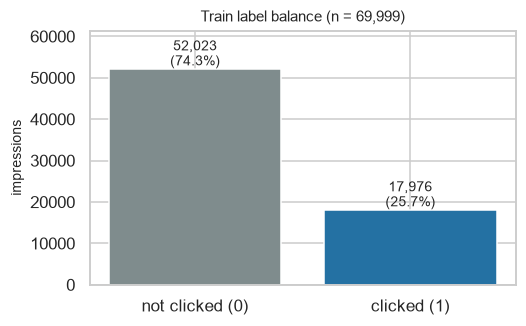

In [7]:
train_ctr, val_ctr, test_ctr = (ctr_row(p["label"]) for p in (train, val, test))
balance = pd.DataFrame({"train": train_ctr, "val": val_ctr, "test": test_ctr}).T
print(balance.to_string())

from sklearn.metrics import log_loss

p0 = train_ctr["ctr"]
const_logloss = log_loss(train["label"], np.full(len(train), p0), labels=[0, 1])
majority_acc = max(p0, 1 - p0)
print()
print("constant predictor p = train CTR {p:.4f}: log loss {ll:.4f}  [= binary entropy of the base rate]".format(p=p0, ll=const_logloss))
print("always-predict-0 accuracy: {a:.4f}  <- the number that flatters a useless model".format(a=1 - p0))
assert abs(const_logloss - (-(p0 * np.log(p0) + (1 - p0) * np.log(1 - p0)))) < 1e-9

fig, ax = plt.subplots(figsize=(5, 3))
counts = train["label"].value_counts().sort_index()
bars = ax.bar(["not clicked (0)", "clicked (1)"], counts.values, color=["#7f8c8d", "#2471a3"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, "{:,}\n({:.1%})".format(v, v / len(train)),
            ha="center", va="bottom")
ax.set_title("Train label balance (n = {:,})".format(len(train)))
ax.set_ylabel("impressions")
ax.set_ylim(0, counts.max() * 1.18)
save_fig(fig, "nb01_class_balance.png")
plt.show()

**What we see.** Roughly three in four impressions do not click. A model that never
predicts a click would score about 74% accuracy while ranking nothing. The constant
predictor's log loss (~0.570) is the entropic floor of "no information" - any model that
cannot beat it on held-out data is worthless regardless of accuracy.

**Implications.**
- Log loss (binary cross-entropy) is the primary metric: it is a *proper scoring rule*,
  so it is minimised only by predicting true probabilities. Accuracy and even AUC can
  look fine while probabilities are unusable for auction decisions.
- We do **not** resample or reweight classes for the primary models. Class weights and
  negative down-sampling change what the predicted probability means (it stops being
  P(click)), so anyone using them must re-calibrate before serving. We train with the
  natural imbalance and measure calibration explicitly in notebook 03 - the damage would
  be visible there.
- The imbalance also caps naive metrics: with PR-AUC (average precision), the no-skill
  level equals the base rate, so it is quoted alongside its baseline everywhere.

## C. Missing values

**Q:** Where are the gaps, do they co-occur in patterns, and does "missing" carry signal?
**Why it matters:** Criteo's missingness is structural, not sprinkles of noise - several
columns vanish together for whole slices of traffic. The fill strategy changes both the
model inputs and the meaning of the result. One thing we will not do is *claim
causation*: with anonymised features we can only say that the missing slice behaves
differently, never why.

columns with missing values in train: 24 of 40
column  n_missing  pct_missing
   I12      53468    76.383948
   C22      53278    76.112516
    I1      31788    45.412077
   I10      31788    45.412077
   C26      30888    44.126345
   C25      30888    44.126345
   C19      30888    44.126345
   C20      30888    44.126345
    I6      15788    22.554608
    I3      15086    21.551736
    I4      15019    21.456021
   I13      15019    21.456021
    C6       8297    11.853026
   I11       3044     4.348634
    I9       3044     4.348634
    I7       3044     4.348634
   C24       2360     3.371477
   C21       2360     3.371477
    C3       2360     3.371477
   C12       2360     3.371477
   C16       2360     3.371477
    C4       2360     3.371477
    I5       1840     2.628609
    I8         35     0.050001


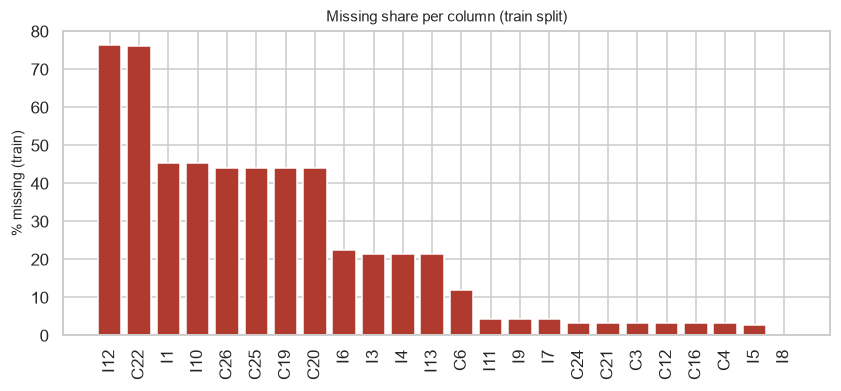

In [8]:
miss = ctr_eda.missing_summary(train)
miss = miss[miss["n_missing"] > 0].reset_index(drop=True)
print("columns with missing values in train: {} of {}".format(len(miss), train.shape[1]))
print(miss.to_string(index=False))
miss.to_csv(TABLE_DIR / "missing_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(miss["column"], miss["pct_missing"], color="#b03a2e")
ax.set_ylabel("% missing (train)")
ax.set_title("Missing share per column (train split)")
plt.xticks(rotation=90)
save_fig(fig, "nb01_missing_per_column.png")
plt.show()

Top missingness patterns in the train split:
 n_rows  pct_rows  n_missing_in_pattern                           columns_missing
   7264 10.377291                     2                                  I12, C22
   4502  6.431520                     6              I12, C19, C20, C22, C25, C26
   3304  4.720067                     1                                       C22
   3039  4.341491                     4                         I1, I10, I12, C22
   2575  3.678624                     1                                       I12
   2404  3.434335                     5                     I1, I6, I10, I12, C22
   2122  3.031472                     8     I1, I10, I12, C19, C20, C22, C25, C26
   1991  2.844326                     5                   C19, C20, C22, C25, C26
   1924  2.748611                     9 I1, I6, I10, I12, C19, C20, C22, C25, C26
   1809  2.584323                     3                              I12, C6, C22


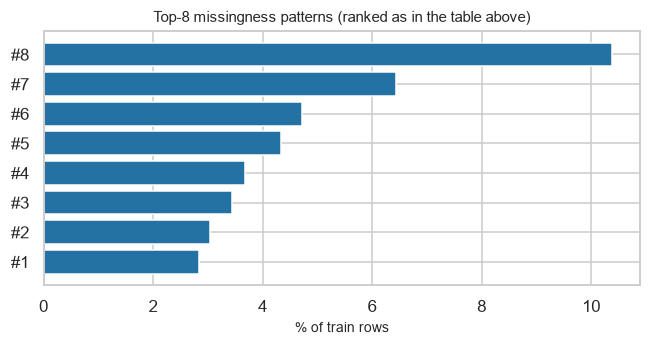

In [9]:
pat = ctr_eda.missing_patterns(train, FEATURE_COLS, top=10)
print("Top missingness patterns in the train split:")
print(pat[["n_rows", "pct_rows", "n_missing_in_pattern", "columns_missing"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
top = pat.head(8).iloc[::-1].reset_index(drop=True)
ax.barh(["#{:d}".format(i + 1) for i in range(len(top))], top["pct_rows"], color="#2471a3")
ax.set_xlabel("% of train rows")
ax.set_title("Top-8 missingness patterns (ranked as in the table above)")
save_fig(fig, "nb01_missing_patterns.png")
plt.show()

Missing vs present CTR, train split (gap = CTR_missing - CTR_present):
column  n_missing  n_present  ctr_missing  ctr_present   gap_pp  cis_overlap  flagged
    I8         35      69964       0.0571       0.2569 -19.9761        False     True
    I6      15788      54211       0.1340       0.2926 -15.8616        False     True
    I5       1840      68159       0.1049       0.2609 -15.6013        False     True
   I10      31788      38211       0.1888       0.3133 -12.4494        False     True
    I1      31788      38211       0.1888       0.3133 -12.4494        False     True
    I7       3044      66955       0.1557       0.2614 -10.5683        False     True
   I11       3044      66955       0.1557       0.2614 -10.5683        False     True
    I9       3044      66955       0.1557       0.2614 -10.5683        False     True
    I3      15086      54913       0.3065       0.2431   6.3361        False     True
   I12      53468      16531       0.2464       0.2905  -4.4173      

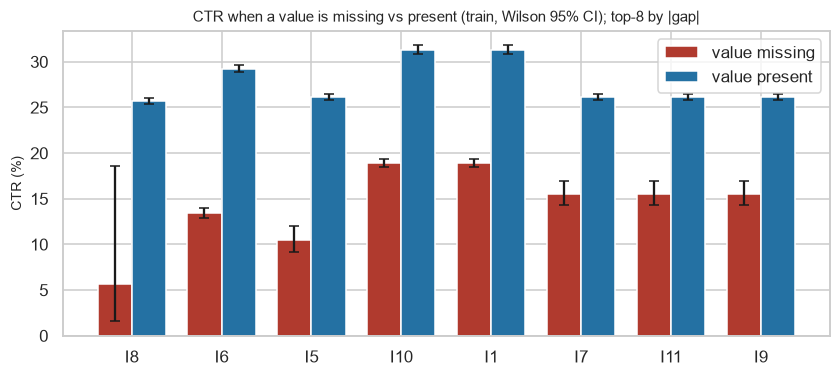


Decision rule (fixed before looking): flag a column when the Wilson CIs of missing
vs present CTR do not overlap AND |gap| >= 0.5 pp (multiple-testing guard).
flagged columns: 23 -> ['I8', 'I6', 'I5', 'I10', 'I1', 'I7', 'I11', 'I9', 'I3', 'I12', 'C12', 'C21', 'C16', 'C3', 'C4', 'C24', 'C22', 'I4', 'I13', 'C26', 'C20', 'C19', 'C25']
=> recommended add_missing_indicators: True


In [10]:
rows = []
for c in miss["column"]:
    m = train[c].isna()
    a, b = ctr_row(train.loc[m, "label"]), ctr_row(train.loc[~m, "label"])
    overlap = not (a["ci_low"] > b["ci_high"] or b["ci_low"] > a["ci_high"])
    rows.append({
        "column": c,
        "n_missing": a["n"], "n_present": b["n"],
        "ctr_missing": a["ctr"], "ctr_present": b["ctr"],
        "gap_pp": 100 * (a["ctr"] - b["ctr"]),
        "ci_low_missing": a["ci_low"], "ci_high_missing": a["ci_high"],
        "ci_low_present": b["ci_low"], "ci_high_present": b["ci_high"],
        "cis_overlap": overlap,
    })
miss_ctr = pd.DataFrame(rows).sort_values("gap_pp", key=lambda s: s.abs(), ascending=False)
miss_ctr["flagged"] = (~miss_ctr["cis_overlap"]) & (miss_ctr["gap_pp"].abs() >= 0.5)
print("Missing vs present CTR, train split (gap = CTR_missing - CTR_present):")
print(miss_ctr[["column", "n_missing", "n_present", "ctr_missing", "ctr_present",
                "gap_pp", "cis_overlap", "flagged"]].round(4).to_string(index=False))
miss_ctr.to_csv(TABLE_DIR / "missing_vs_present_ctr.csv", index=False)

top8 = miss_ctr.head(8)
x = np.arange(len(top8))
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.38
err_m = np.vstack([top8["ctr_missing"] - top8["ci_low_missing"], top8["ci_high_missing"] - top8["ctr_missing"]])
err_p = np.vstack([top8["ctr_present"] - top8["ci_low_present"], top8["ci_high_present"] - top8["ctr_present"]])
ax.bar(x - w / 2, 100 * top8["ctr_missing"], w, yerr=100 * err_m, capsize=3,
       label="value missing", color="#b03a2e")
ax.bar(x + w / 2, 100 * top8["ctr_present"], w, yerr=100 * err_p, capsize=3,
       label="value present", color="#2471a3")
ax.set_xticks(x)
ax.set_xticklabels(top8["column"])
ax.set_ylabel("CTR (%)")
ax.set_title("CTR when a value is missing vs present (train, Wilson 95% CI); top-8 by |gap|")
ax.legend()
save_fig(fig, "nb01_ctr_by_missingness.png")
plt.show()

flagged = miss_ctr.loc[miss_ctr["flagged"], "column"].tolist()
decision_ind = len(flagged) > 0
print()
print("Decision rule (fixed before looking): flag a column when the Wilson CIs of missing")
print("vs present CTR do not overlap AND |gap| >= 0.5 pp (multiple-testing guard).")
print("flagged columns: {} -> {}".format(len(flagged), flagged))
print("=> recommended add_missing_indicators:", decision_ind)

**What we see.** Missingness is far from uniform: a handful of columns are missing for
very large slices of traffic, and the top patterns show that gaps travel in groups -
`I1` and `I10` are missing on exactly the same rows, as are `C3 / C4 / C12 / C16 / C21 /
C24` (identical missing counts and identical CTRs in the table above) - so several
"missing slices" are really one slice. Whether that slice clicks differently is what the
missing-vs-present table quantifies; each gap comes with its sample size and Wilson
interval, and the flagging rule (non-overlapping CIs plus a 0.5 pp minimum) guards
against calling tiny differences on huge samples meaningful. One flagged column (`I8`)
has only 35 missing rows in train - an indicator for it is nearly free but nearly
constant; the substantive flags are the other 22.

**Plan (decided here, applied in notebook 02).**
- Numeric gaps -> train-median imputation. Medians are computed on the train split only
  and frozen; rows are never dropped (dropping rows for the ~76%-missing columns would
  delete most of the data).
- Categorical gaps -> the shared OOV index 0, which already means "unknown" for rare and
  unseen values. Missing is not invented as a new semantic category.
- Missing indicators: the a-priori rule flags 23 of the 24 gappy columns (`C6` is the
  one failure - its Wilson CIs overlap), so `config.yaml` sets
  `add_missing_indicators: true` and records those 23 columns in
  `missing_indicator_columns`; each contributes one 0/1 input in notebook 02. Notebook 02
  can ablate this against imputation-only if the models show it is carrying no weight.
- No causal claims: the table describes co-behaviour of a missing slice, and the
  missing flag may proxy for traffic types whose meaning is anonymised away.

## D. Numeric columns (I1-I13)

**Q:** What shape are the numeric distributions - skew, zeros, ranges - and do they
separate clickers from non-clickers?
**Why it matters:** transform and imputation choices depend on distribution shape.
The I columns are anonymised: we describe their distributions numerically and never
assign them meanings like "price" or "age".

In [11]:
def numeric_profile(frame, cols):
    out = []
    for c in cols:
        x = frame[c].astype("float64")
        n = int(x.notna().sum())
        row = {"column": c, "non_null": n, "missing_pct": 100 * (1 - n / len(frame)),
               "min": x.min(), "mean": x.mean(), "std": x.std(),
               "max": x.max(), "zero_pct": 100 * (x == 0).mean(), "neg_pct": 100 * (x < 0).mean(),
               "skew_raw": x.skew()}
        row.update({"p{:.0f}".format(p * 100): x.quantile(p) for p in (0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99)})
        out.append(row)
    cols_order = ["column", "non_null", "missing_pct", "min", "p1", "p5", "p25", "p50",
                  "p75", "p95", "p99", "max", "mean", "std", "zero_pct", "neg_pct", "skew_raw"]
    return pd.DataFrame(out)[cols_order]


prof = numeric_profile(train, NUM_COLS)
print("Numeric descriptives (train split):")
print(prof.round(3).to_string(index=False))
prof.to_csv(TABLE_DIR / "numeric_descriptives.csv", index=False)

Numeric descriptives (train split):
column  non_null  missing_pct  min   p1   p5   p25    p50     p75     p95       p99       max      mean       std  zero_pct  neg_pct  skew_raw
    I1     38211       45.412  0.0  0.0  0.0   0.0    1.0     3.0    15.0     39.00     531.0     3.530     9.682    23.247    0.000    13.810
    I2     69999        0.000 -2.0 -1.0 -1.0   0.0    3.0    35.0   497.0   2184.02    8673.0   103.684   384.667    17.489   10.367     6.919
    I3     54913       21.552  0.0  1.0  1.0   2.0    6.0    18.0    76.0    212.00   33988.0    28.618   440.364     0.327    0.000    58.389
    I4     54980       21.456  0.0  0.0  0.0   2.0    4.0    10.0    25.0     41.00     143.0     7.291     8.589     4.174    0.000     2.478
    I5     68159        2.629  0.0  0.0  2.0 322.0 2813.0 10156.0 64938.6 358715.66 1661556.0 18711.968 68987.376     1.894    0.000     8.706
    I6     54211       22.555  0.0  0.0  0.0   8.0   33.0   103.0   480.0   1257.00   27422.0   116.512   

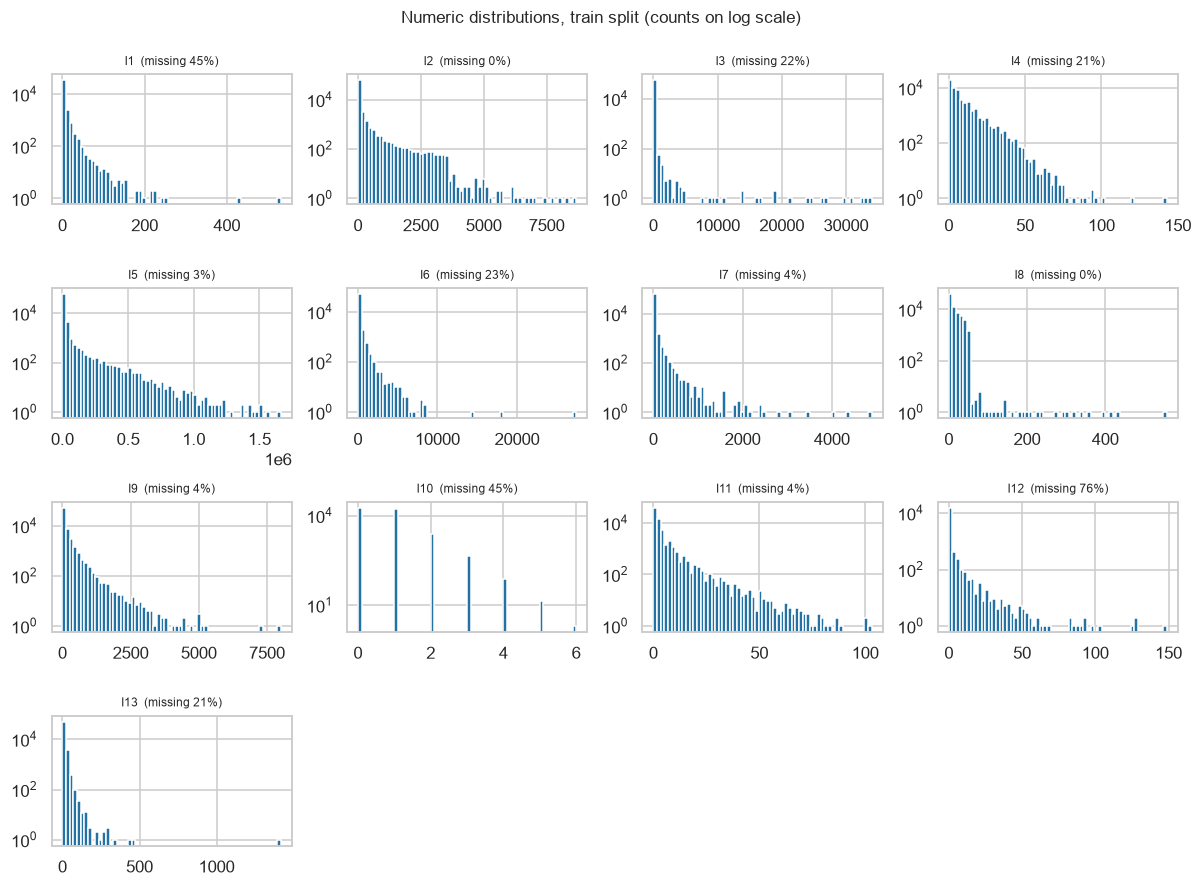

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(11, 8))
for ax, c in zip(axes.ravel(), NUM_COLS):
    x = train[c].dropna()
    ax.hist(x, bins=60, color="#2471a3")
    ax.set_yscale("log")
    ax.set_title("{}  (missing {:d}%)".format(c, int(round(100 * train[c].isna().mean()))), fontsize=8)
for ax in axes.ravel()[len(NUM_COLS):]:
    ax.axis("off")
fig.suptitle("Numeric distributions, train split (counts on log scale)", y=1.0)
fig.tight_layout()
save_fig(fig, "nb01_numeric_histograms.png")
plt.show()

columns selected for sign-preserving log1p (|skew| > 2.0): 12 of 13 -> ['I1', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'I11', 'I12', 'I13']
range check: 1 of 13 columns contain negative values (plain log would be invalid); skewness is computed on train only, never on val/test

Skew before/after the fitted transform (train only):
column  skew_raw  skew_after_log1p
    I1    13.810             1.733
    I2     6.919             0.733
    I3    58.389             1.039
    I4     2.478             0.305
    I5     8.706            -0.769
    I6    21.172            -0.169
    I7    25.668             0.758
    I8     4.037            -0.251
    I9     7.709            -0.204
   I11     5.779             1.001
   I12    14.301             6.557
   I13    27.981             0.381


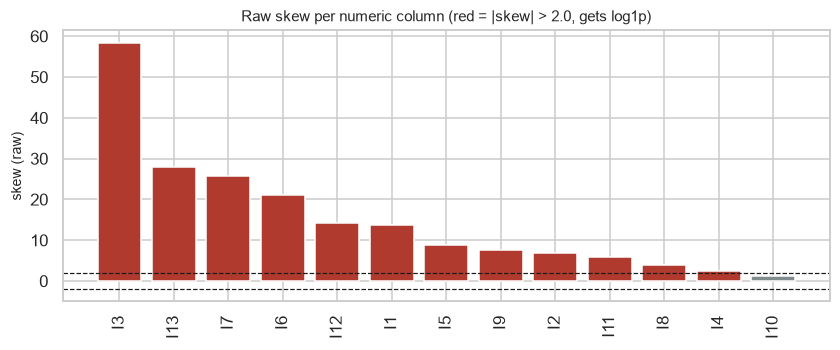

In [13]:
thr = float(cfg["features"]["skew_threshold"])
sk = prof.set_index("column")[["skew_raw", "zero_pct", "neg_pct"]].sort_values(
    "skew_raw", key=lambda s: s.abs(), ascending=False)
log_cols = [c for c in NUM_COLS if abs(train[c].astype("float64").skew()) > thr]
print("columns selected for sign-preserving log1p (|skew| > {:.1f}): {} of 13 -> {}".format(
    thr, len(log_cols), log_cols))
print("range check: {} of 13 columns contain negative values (plain log would be invalid); "
      "skewness is computed on train only, never on val/test".format(int((prof["neg_pct"] > 0).sum())))

chk = []
for c in log_cols:
    x = train[c].astype("float64")
    xf = x.fillna(x.median())
    xl = np.sign(xf) * np.log1p(np.abs(xf))
    chk.append({"column": c, "skew_raw": x.skew(), "skew_after_log1p": xl.skew()})
chk = pd.DataFrame(chk)
print()
print("Skew before/after the fitted transform (train only):")
print(chk.round(3).to_string(index=False))
assert np.isfinite(chk["skew_after_log1p"]).all()

fig, ax = plt.subplots(figsize=(9, 3.2))
colors = ["#b03a2e" if abs(v) > thr else "#7f8c8d" for v in sk["skew_raw"]]
ax.bar(sk.index, sk["skew_raw"], color=colors)
ax.axhline(thr, ls="--", c="k", lw=0.8)
ax.axhline(-thr, ls="--", c="k", lw=0.8)
ax.set_ylabel("skew (raw)")
ax.set_title("Raw skew per numeric column (red = |skew| > {:.1f}, gets log1p)".format(thr))
plt.xticks(rotation=90)
save_fig(fig, "nb01_numeric_skew.png")
plt.show()

In [14]:
rows = []
for c in NUM_COLS:
    a = train.loc[train["label"] == 1, c].dropna()
    b = train.loc[train["label"] == 0, c].dropna()
    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    rows.append({"column": c, "mean_clicked": a.mean(), "mean_not": b.mean(),
                 "median_clicked": a.median(), "median_not": b.median(),
                 "cohens_d": (a.mean() - b.mean()) / pooled if pooled else np.nan})
sep = pd.DataFrame(rows).sort_values("cohens_d", key=lambda s: s.abs(), ascending=False)
print("Clicked vs not - effect sizes (train; |d| < 0.2 is small, > 0.5 medium):")
print(sep.round(3).to_string(index=False))
sep.to_csv(TABLE_DIR / "numeric_clicked_vs_not.csv", index=False)
print()
print("With n ~ 70k, p-values are uninformative (everything is 'significant'); effect")
print("sizes and intervals are the honest summary. These are raw-scale comparisons; the")
print("fitted log1p transform reshapes magnitudes, not signs.")

Clicked vs not - effect sizes (train; |d| < 0.2 is small, > 0.5 medium):
column  mean_clicked  mean_not  median_clicked  median_not  cohens_d
   I10         0.780     0.536             1.0         0.0     0.353
   I11         4.033     2.245             2.0         1.0     0.323
   I13         5.950     8.877             3.0         5.0    -0.251
    I6        64.294   138.108            14.0        43.0    -0.249
    I5      9182.363 22075.970          1382.0      3444.0    -0.212
   I12         1.564     0.661             0.0         0.0     0.174
    I1         4.697     2.998             2.0         1.0     0.171
    I7        25.295    13.353             6.0         2.0     0.156
    I4         6.435     7.575             4.0         4.0    -0.137
    I2       140.851    90.841             3.5         3.0     0.120
    I8        11.730    12.839             7.0         8.0    -0.081
    I9       114.187   103.192            37.0        39.0     0.049
    I3        40.519    24.794

CTR (%) per equal-count decile (train). Each decile holds about 6,999 rows.
        d1     d2     d3     d4     d5     d6     d7     d8     d9    d10
I1   21.85  23.27  22.72  23.29  29.44  32.90  35.38  38.65  42.50  43.34
I2   30.83  24.04  23.33  23.54  22.57  22.27  24.64  24.79  27.51  33.28
I3   28.90  29.32  28.48  27.70  25.02  24.64  23.09  20.89  18.69  16.43
I4   30.76  27.41  27.74  25.54  24.17  23.59  24.08  23.79  22.57  19.70
I5   48.27  31.95  27.89  29.34  26.12  23.96  21.46  20.79  18.34  12.78
I6   54.87  43.72  35.99  30.42  26.53  24.92  22.71  20.33  18.48  14.61
I7   13.72  12.80  18.79  22.27  24.69  27.38  29.75  33.29  36.16  42.55
I8   30.88  28.51  28.18  24.28  24.13  25.87  23.89  23.04  24.23  23.89
I9   30.29  27.18  26.33  24.93  23.48  22.96  24.21  25.68  27.20  29.16
I10  22.42  24.99  23.61  25.60  26.04  34.78  36.64  35.96  36.12  47.19
I11  13.62  13.05  20.04  24.76  23.43  23.66  29.57  31.37  37.27  44.63
I12  25.27  26.98  26.80  26.50  27.

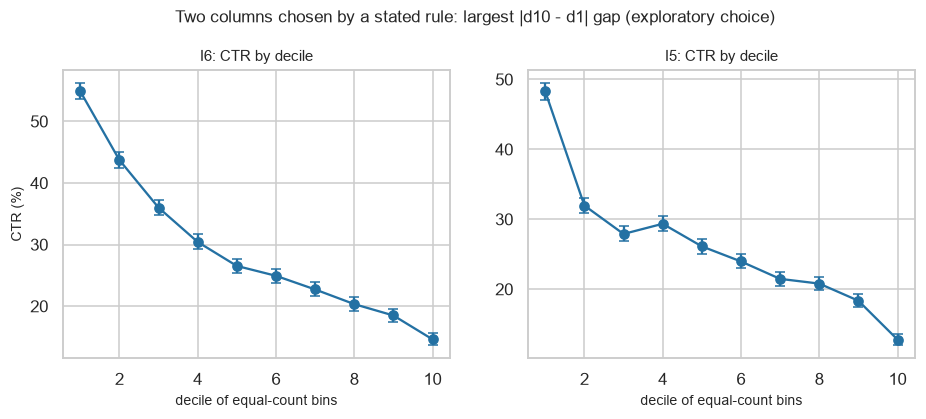

bins are equal-count rank bins (the NTILE convention); tied values may split across bins.


In [15]:
deciles = {c: ctr_eda.ctr_by_rank_bins(train, c, q=10).set_index("bin")["ctr"] for c in NUM_COLS}
dec_mat = pd.DataFrame(deciles).T
dec_mat.columns = ["d{}".format(i) for i in range(1, 11)]
print("CTR (%) per equal-count decile (train). Each decile holds about {:,} rows.".format(int(len(train) / 10)))
print((100 * dec_mat).round(2).to_string())
dec_mat.to_csv(TABLE_DIR / "numeric_ctr_by_decile.csv")

gaps = dec_mat["d10"] - dec_mat["d1"]
print()
print("top-decile minus bottom-decile CTR (percentage points):")
print((100 * gaps.sort_values(key=lambda s: s.abs(), ascending=False)).round(2).to_string())

chosen = list(gaps.abs().sort_values(ascending=False).head(2).index)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, c in zip(axes, chosen):
    t = ctr_eda.ctr_by_rank_bins(train, c, q=10)
    ax.errorbar(t["bin"], 100 * t["ctr"],
                yerr=[100 * (t["ctr"] - t["ci_low"]), 100 * (t["ci_high"] - t["ctr"])],
                marker="o", capsize=3, color="#2471a3")
    ax.set_title("{}: CTR by decile".format(c))
    ax.set_xlabel("decile of equal-count bins")
axes[0].set_ylabel("CTR (%)")
fig.suptitle("Two columns chosen by a stated rule: largest |d10 - d1| gap (exploratory choice)", y=1.04)
save_fig(fig, "nb01_ctr_by_decile.png")
plt.show()
print("bins are equal-count rank bins (the NTILE convention); tied values may split across bins.")

**What we see.** The numeric columns are long right tails with mass at zero (see the
zero shares above), which is exactly where the |skew| threshold bites: 12 of 13 columns
are flagged, and the one column with negative values (`I2`) is why the transform must be
sign-preserving rather than a plain log. The before/after table shows `log1p` collapsing
|skew| from 2.5-58 down to mostly under 1.7; `I12` improves from 14.3 to 6.6 but stays
heavy - the goal is compression of the tail, not normality. Clicked and not-clicked rows
differ with small-to-moderate effect sizes (max |Cohen's d| = 0.35 for `I10`), and the
decile matrix shows real structure: `I6` swings from 54.9% to 14.6% CTR across deciles
(a 40 pp spread), `I5` falls 35 pp, `I11` rises 31 pp. Univariate signal is genuine but
uneven - some columns (`I2`, `I9`) barely move across deciles.

**Decisions.**
- Sign-preserving log1p for columns above the skew threshold, fitted (i.e. the threshold
  applied) on train only; the range check above motivates the sign-preserving form.
- Standardisation to z-scores with train-only means/stds.
- **No outlier removal.** The features are anonymised, so "extreme" has no semantic
  meaning; extreme ranges may be legitimate traffic. L2-regularised linear models and
  tree splits tolerate tails, and dropping rows would corrupt the impression
  distribution. If evaluation shows tail sensitivity, that becomes a modelling
  experiment - not reflexive cleaning.
- Imputation: train medians, applied to every partition (keeps all rows).

## E. Categorical columns (C1-C26)

**Q:** How large are the vocabularies, how heavy is the long tail, and which categories
look predictive?
**Why it matters:** vocabulary design rules the model's memory and the fate of rare
values. Ranking categories by raw CTR without a support filter is the classic EDA
trap - the leaderboard fills with values seen a handful of times. Category IDs are
anonymised hex hashes and are displayed exactly as stored; no meaning is guessed.

In [16]:
rows = []
for c in CAT_COLS:
    s = train[c]
    vc = s.value_counts(dropna=True)
    rows.append({
        "column": c, "n_levels": int(vc.size),
        "top1_share_pct": 100 * float(vc.iloc[0]) / s.notna().sum(),
        "levels_ge_10": int((vc >= 10).sum()),
        "rows_in_levels_lt_10_pct": 100 * float(vc[vc < 10].sum()) / len(train),
        "rows_in_levels_lt_50_pct": 100 * float(vc[vc < 50].sum()) / len(train),
        "max_level_n": int(vc.max()), "missing_pct": 100 * s.isna().mean(),
    })
cat_prof = pd.DataFrame(rows).sort_values("n_levels", ascending=False).reset_index(drop=True)
print("Categorical profile (train split):")
print(cat_prof.round(2).to_string(index=False))
cat_prof.to_csv(TABLE_DIR / "categorical_profile.csv", index=False)

Categorical profile (train split):


column  n_levels  top1_share_pct  levels_ge_10  rows_in_levels_lt_10_pct  rows_in_levels_lt_50_pct  max_level_n  missing_pct
    C3     34092            2.51           540                     57.52                     70.51         1695         3.37
   C12     31424            2.51           556                     53.94                     67.39         1695         3.37
   C21     29388            2.51           580                     51.27                     64.64         1695         3.37
   C16     26490            2.51           628                     47.86                     62.25         1695         3.37
    C4     19566            3.54           714                     39.57                     56.05         2392         3.37
   C10     10124           22.22          1066                     27.59                     52.96        15555         0.00
   C24      9745            5.44           706                     23.19                     39.24         3682         3.37

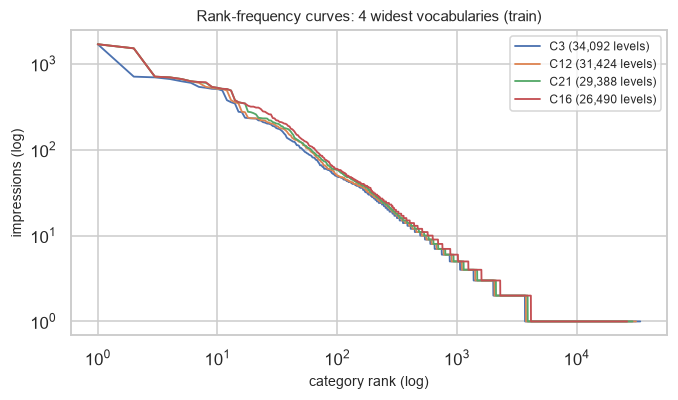

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for c in cat_prof["column"].head(4):
    vc = train[c].value_counts()
    ax.plot(np.arange(1, len(vc) + 1), vc.to_numpy(), lw=1.2, label="{} ({:,} levels)".format(c, len(vc)))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("category rank (log)")
ax.set_ylabel("impressions (log)")
ax.set_title("Rank-frequency curves: 4 widest vocabularies (train)")
ax.legend(fontsize=8)
save_fig(fig, "nb01_category_longtail.png")
plt.show()

In [18]:
def with_ci(tbl):
    ci = [ctr_eda.wilson_ci(int(k), int(n)) for k, n in zip(tbl["clicks"], tbl["n"])]
    out = tbl.copy()
    out["ci_low"] = [c[0] for c in ci]
    out["ci_high"] = [c[1] for c in ci]
    return out


min_count = int(cfg["features"]["min_category_count"])
t = ctr_eda.category_ctr_table(train, "C1", min_support=min_count, prior=prior, strength=50)
oov_pct = 100 * (1 - t["n"].sum() / len(train))
print("C1: {:,} levels with >= {} train rows; rows outside the vocabulary (OOV): {:.2f}%".format(
    len(t), min_count, oov_pct))

top_raw = with_ci(t.sort_values("ctr", ascending=False).head(10))
top_sm = with_ci(t.sort_values("ctr_smoothed", ascending=False).head(10))
print()
print("Top-10 C1 by RAW CTR (support >= {}):".format(min_count))
print(top_raw[["n", "clicks", "ctr", "ci_low", "ci_high"]].round(4).to_string())
print()
print("Top-10 C1 by SMOOTHED CTR (empirical-Bayes toward prior {:.4f}, strength 50):".format(prior))
print(top_sm[["n", "clicks", "ctr", "ctr_smoothed"]].round(4).to_string())
print()
print("median support: raw top-10 = {} rows | smoothed top-10 = {} rows".format(
    int(top_raw["n"].median()), int(top_sm["n"].median())))
assert top_raw["n"].median() < top_sm["n"].median(), "expected smoothed ranking to prefer better-supported categories"

C1: 87 levels with >= 10 train rows; rows outside the vocabulary (OOV): 1.05%

Top-10 C1 by RAW CTR (support >= 10):
           n  clicks     ctr  ci_low  ci_high
C1                                           
06584483  12       6  0.5000  0.2538   0.7462
c2a5852e  14       6  0.4286  0.2138   0.6741
7ceef477  10       4  0.4000  0.1682   0.6873
c35dc981  26      10  0.3846  0.2243   0.5747
9e9d28f5  13       5  0.3846  0.1771   0.6448
a86f8721  11       4  0.3636  0.1517   0.6462
f0a33555  11       4  0.3636  0.1517   0.6462
0a16e1d4  20       7  0.3500  0.1812   0.5671
9684fd4d  41      14  0.3415  0.2156   0.4945
8c6ba407  36      12  0.3333  0.2021   0.4967

Top-10 C1 by SMOOTHED CTR (empirical-Bayes toward prior 0.2568, strength 50):
            n  clicks     ctr  ctr_smoothed
C1                                         
06584483   12       6  0.5000        0.3039
c35dc981   26      10  0.3846        0.3005
9684fd4d   41      14  0.3415        0.2949
c2a5852e   14       6  0.4286   

In [19]:
labels = ["<10 (OOV slot)", "10-49", "50-199", "200+"]
band_of = pd.cut(train["C1"].value_counts(), bins=[-1, 9, 49, 199, np.inf], labels=labels)
rows = []
for lab in labels:
    levels = band_of[band_of == lab].index
    m = train["C1"].isin(levels)
    r = ctr_row(train.loc[m, "label"])
    r["band"] = lab
    r["levels"] = len(levels)
    rows.append(r)
band_tbl = pd.DataFrame(rows)[["band", "levels", "n", "ctr", "ci_low", "ci_high"]]
print("C1 support bands (train):")
print(band_tbl.round(4).to_string(index=False))

vocab = {c: int(cat_prof.set_index("column").loc[c, "levels_ge_10"]) + 1 for c in CAT_COLS}
width = sum(vocab.values())
print()
print("vocabulary widths: one-hot (LR) prefix = {:,} columns + {} numerics".format(width, len(NUM_COLS)))
print("embedding tables (DeepFM, k=8 float32): {:,} params = {:.1f} MB".format(width * 8, width * 8 * 4 / 1e6))
print("LightGBM native categoricals: 26 int32 columns/row = {} bytes/row (codes, not one-hot)".format(26 * 4))

C1 support bands (train):
          band  levels     n    ctr  ci_low  ci_high
<10 (OOV slot)     356   733 0.2647  0.2340   0.2978
         10-49      48   944 0.2447  0.2183   0.2731
        50-199      21  1909 0.2588  0.2396   0.2789
          200+      18 66413 0.2568  0.2535   0.2602

vocabulary widths: one-hot (LR) prefix = 12,070 columns + 13 numerics
embedding tables (DeepFM, k=8 float32): 96,560 params = 0.4 MB
LightGBM native categoricals: 26 int32 columns/row = 104 bytes/row (codes, not one-hot)


**What we see.** The vocabularies span four orders of magnitude - from `C3` with 34,092
distinct values in train down to near-binary columns with 3-11 - and for the widest
columns most traffic sits in levels below the support threshold (57.5% of train rows for
`C3`, 51.7% of row-value pairs outside the >=10 vocabulary pool-wide per the SQL check),
while for `C1` only 1.05% of rows fall outside. The raw-CTR leaderboard confirms the
classic trap: the top raw values are levels with 10-41 impressions carrying 33-50% CTR
and intervals spanning 0.15-0.75; the smoothed ranking (empirical-Bayes toward the
global prior, strength 50) shifts the top-10's median support from 13 to 41 rows. For
`C1` the support bands are nearly indistinguishable (OOV band 26.5% CTR vs 25.7% for
200+ levels, overlapping intervals) - the "unknown" mass behaves like the known mass for
this column, which is a useful baseline expectation for the OOV slot in the models, not
a law; other columns' bands can be checked the same way.

**Decisions.**
- `min_category_count = 10` on train: levels with at least 10 train rows get an index;
  everything else shares OOV index 0. This is a judgment call balancing vocabulary
  breadth against per-level reliability - visible in the support bands.
- LR sees one-hot counts; LightGBM sees integer codes declared as native categoricals;
  DeepFM learns 8-dimensional embeddings. Notebook 02 measures what each option buys.
- The OOV and missing slot is a *single* bucket: the model can only learn "unknown", not
  which flavour of unknown - a simplification stated for transparency (missing
  indicators, enabled per section C, partially recover the distinction).

## F. A first look at interactions

**Q:** Do features interact - does one feature's effect on CTR depend on another?
**Why it matters:** the FM and deep components of DeepFM exist to learn interactions.
EDA should suggest whether there is headroom beyond an additive model. Two honesty
rules apply: (1) we deliberately limit this to one numeric-numeric pair and one
numeric-categorical pair chosen by stated rules, because scanning hundreds of
combinations guarantees chance "discoveries" (multiple comparisons); (2) everything
here is a *hypothesis* to test on validation data, not a fact - cells have limited
support and apparent patterns may be noise.

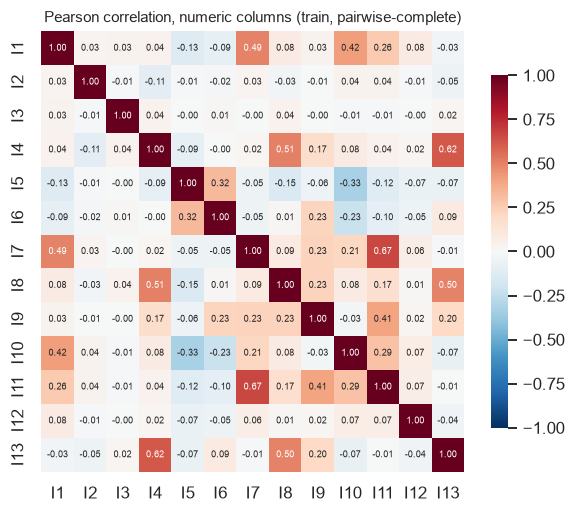

strongest |r| pairs (each unordered pair once):
I11  I7     0.667
I13  I4     0.623
I4   I8     0.506
I13  I8     0.497
I1   I7     0.495
     I10    0.418

pairs with |r| >= 0.5: 3 -> ['I11~I7 r=0.67', 'I13~I4 r=0.62', 'I4~I8 r=0.51']


In [20]:
corr = train[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 6}, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Pearson correlation, numeric columns (train, pairwise-complete)")
save_fig(fig, "nb01_correlation_heatmap.png")
plt.show()

# keep one row per unordered pair (drop the mirror entry)
pairs = corr.where(~np.eye(len(NUM_COLS), dtype=bool)).stack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
pairs = pairs.sort_values(key=lambda s: s.abs(), ascending=False)
print("strongest |r| pairs (each unordered pair once):")
print(pairs.head(6).round(3).to_string())
strong = pairs[pairs.abs() >= 0.5]
print()
print("pairs with |r| >= 0.5: {} -> {}".format(
    len(strong), ["{}~{} r={:.2f}".format(a, b, r) for (a, b), r in strong.items()]))

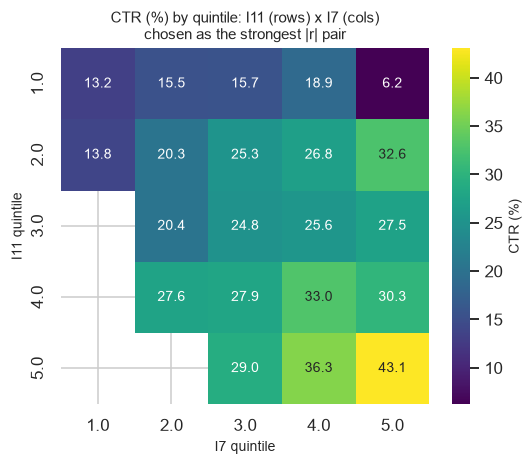

cell row counts: min 16 / max 12853


In [21]:
(p1, p2) = pairs.index[0]
cell = pd.DataFrame({
    "a": ctr_eda.rank_bins(train[p1], 5),
    "b": ctr_eda.rank_bins(train[p2], 5),
    "y": train["label"].to_numpy(),
}).dropna()
piv = cell.pivot_table(index="a", columns="b", values="y", aggfunc="mean")
cnt = cell.pivot_table(index="a", columns="b", values="y", aggfunc="size")

fig, ax = plt.subplots(figsize=(5.4, 4.2))
sns.heatmap(100 * piv, annot=True, fmt=".1f", cmap="viridis", ax=ax,
            cbar_kws={"label": "CTR (%)"})
ax.set_title("CTR (%) by quintile: {} (rows) x {} (cols)\nchosen as the strongest |r| pair".format(p1, p2))
ax.set_xlabel("{} quintile".format(p2))
ax.set_ylabel("{} quintile".format(p1))
save_fig(fig, "nb01_ctr_pair_heatmap.png")
plt.show()
print("cell row counts: min {} / max {}".format(int(cnt.min().min()), int(cnt.max().max())))

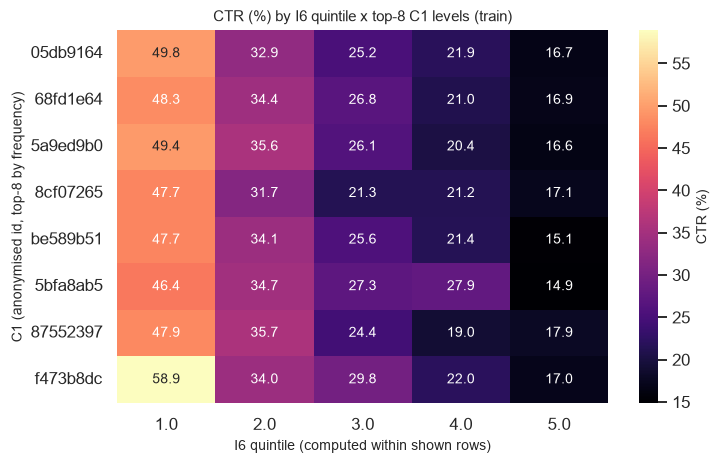

cell row counts: min 141 / max 5477


In [22]:
num_for_heat = chosen[0]
top_levels = train["C1"].value_counts().head(8).index
sub = train[train["C1"].isin(top_levels)].copy()
sub["q"] = ctr_eda.rank_bins(sub[num_for_heat], 5)
piv = sub.pivot_table(index="C1", columns="q", values="label", aggfunc="mean").reindex(top_levels)
cnt = sub.pivot_table(index="C1", columns="q", values="label", aggfunc="size").reindex(top_levels)

fig, ax = plt.subplots(figsize=(7.2, 4.4))
sns.heatmap(100 * piv, annot=True, fmt=".1f", cmap="magma", ax=ax,
            cbar_kws={"label": "CTR (%)"})
ax.set_title("CTR (%) by {} quintile x top-8 C1 levels (train)".format(num_for_heat))
ax.set_xlabel("{} quintile (computed within shown rows)".format(num_for_heat))
ax.set_ylabel("C1 (anonymised id, top-8 by frequency)")
save_fig(fig, "nb01_ctr_numcat_heatmap.png")
plt.show()
print("cell row counts: min {} / max {}".format(int(cnt.min().min()), int(cnt.max().max())))

**What we see.** The numeric block is mostly well-behaved but not orthogonal: the
strongest unique pair is `I11`-`I7` at |r| = 0.67, followed by `I4`-`I13` (0.62) and
`I4`-`I8` (0.51); everything else is far below. All columns are kept - correlated inputs
are handled (regularisation shrinks the linear twins, trees pick one) - but the strongest
pair gets the interaction heatmap because correlated twins are also the natural
candidates for genuine joint effects. One honesty flag sits under both heatmaps: the
strongest pair's grid includes a corner supported by ~16 rows and the categorical grid
goes down to ~141; those are exactly the cells where chance patterns hide, so nothing
downstream depends on any single cell - the models get to test these hypotheses on
validation data instead.

**What this means for modelling.** This is the motivation for the models in notebook 02:
tree ensembles split greedily on interactions, the FM component learns every pairwise
embedding dot-product (data-efficiently, even for rarely co-occurring pairs), and the
deep component adds higher-order structure. Whether they actually deliver on this
dataset is an empirical question answered on validation data - EDA raises the
hypothesis, it does not settle it.

## H. Train vs validation: partition comparison

**Q:** Is the validation split a fair stand-in for the training distribution?
**Why it matters:** if validation differs systematically - missingness, category mixes,
base rate - then model selection on it silently optimises the wrong thing. With a
random split the differences should look like sampling noise, and this section verifies
that rather than assuming it. This is explicitly *not* a temporal-drift analysis: no
timestamps exist, so drift is out of scope by data availability, not by choice.

max KS across 13 numeric columns: 0.0148 (I3)
column  ks_stat  p_value  mean_train   mean_val  missing_pct_train  missing_pct_val
    I1   0.0076   0.8254      3.5303     3.4756            45.4121          45.6097
    I2   0.0051   0.9035    103.6841   102.6830             0.0000           0.0000
    I3   0.0148   0.0283     28.6175    25.9629            21.5517          21.6281
    I4   0.0099   0.2962      7.2907     7.1617            21.4560          21.8281
    I5   0.0054   0.8773  18711.9681 18829.7008             2.6286           2.4802
    I6   0.0053   0.9519    116.5116   119.3596            22.5546          22.4615
    I7   0.0071   0.5911     16.4748    16.0517             4.3486           4.1736
    I8   0.0066   0.6494     12.5539    12.4319             0.0500           0.0467
    I9   0.0109   0.1195    106.0664   102.3892             4.3486           4.1736
   I10   0.0031   1.0000      0.6128     0.6092            45.4121          45.6097
   I11   0.0090   0.2946      


unseen category levels: worst column C3 with 44.44% of val rows
column  train_levels  val_levels  val_rows_unseen_pct
    C1           443         203                0.327
    C2           509         437                0.027
    C3         34092        8536               44.435
    C4         19566        5789               21.162
    C5           113          72                0.067
    C6            11          10                0.000
    C7          7322        4109                2.860
    C8           218         102                0.080
    C9             3           3                0.000
   C10         10124        4227                7.247
   C11          3721        2524                0.967
   C12         31424        8042               40.647
   C13          2806        2038                0.407
   C14            26          25                0.000
   C15          4720        2580                2.160
   C16         26490        7116               32.630
   C17           

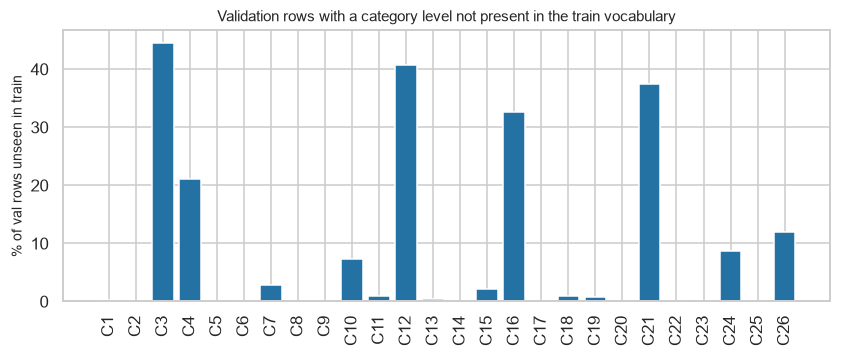

In [23]:
ks = ctr_eda.ks_table(train, val, NUM_COLS)
top_ks = ks.loc[ks["ks_stat"].idxmax()]
print("max KS across 13 numeric columns: {:.4f} ({})".format(top_ks["ks_stat"], top_ks["column"]))
print(ks.round(4).to_string(index=False))
print()
print("missingness train vs val: max |diff| = {:.3f} pp".format(
    (ks["missing_pct_train"] - ks["missing_pct_val"]).abs().max()))
ks.to_csv(TABLE_DIR / "ks_train_val.csv", index=False)
assert ks["ks_stat"].max() < 0.02, "numeric distributions differ between train and val beyond sampling noise"

ov = ctr_eda.category_overlap_table(train, val, CAT_COLS)
worst = ov.loc[ov["val_rows_unseen_pct"].idxmax()]
print()
print("unseen category levels: worst column {} with {:.2f}% of val rows".format(
    worst["column"], worst["val_rows_unseen_pct"]))
print(ov.round(3).to_string(index=False))
ov.to_csv(TABLE_DIR / "category_overlap.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(ov["column"], ov["val_rows_unseen_pct"], color="#2471a3")
ax.set_ylabel("% of val rows unseen in train")
ax.set_title("Validation rows with a category level not present in the train vocabulary")
plt.xticks(rotation=90)
save_fig(fig, "nb01_val_unseen_categories.png")
plt.show()

**What we see.** Numeric partitions match closely: the largest KS statistic is 0.0148
(`I3`, nominal p = 0.028 - the one result out of 13 comparisons that wobbles slightly,
which is what a 5% test expects to produce at this seed), everything else is at
noise level, missingness matches within 0.4 pp, and the base rates agree to within
0.003 pp. The one number to carry into notebook 03 is the unseen-category share: the
widest vocabularies route large slices of validation traffic to OOV (`C3` 44.4%, `C12`
40.6%, `C21` 37.4%, `C16` 32.6% of val rows), while mid and narrow columns stay in the
0-12% range. Those are exactly the levels that were rare (<10 rows) in train, so this is
the vocab decision from section E showing up as a measurable serving condition.

**Limitation, stated plainly.** These checks validate a *random* partition of
exchangeable rows. They say nothing about how the model would face tomorrow's traffic -
no timestamp exists to build or test a temporal split, so temporal generalisation
remains untested by construction.

## SQL cross-checks (DuckDB)

**Q:** Do the Python numbers survive an independent engine?
**Why it matters:** in practice these numbers live in a warehouse, not a notebook.
The repo ships five SQL files under `sql/` that DuckDB runs directly against the
parquet file; the same statements would run on BigQuery or Snowflake with only the
table reference changed. Here we re-run the shipped files and *assert* agreement with
the pandas computations - two engines agreeing exactly is a strong correctness signal.

**Conventions to watch:** SQL `GROUP BY` treats `NULL` as a group value (pandas mirrors
use `dropna=False` where that matters); `NTILE` assigns tied rows to bins in
implementation-defined order, so per-bin CTR can wobble slightly while totals agree
exactly - that is a documented property, not an error.

In [24]:
con = sql_runner.connect(sample_path)
sql_res = sql_runner.run_dir(con, PROJECT_ROOT / "sql",
                             params={"min_support": int(cfg["features"]["min_category_count"])})
print("ran:", ", ".join(sorted(sql_res)))

ovl = sql_res["01_overview"]
assert int(ovl["impressions"][0]) == len(sample)
assert int(ovl["clicks"][0]) == int(sample["label"].sum())
assert abs(float(ovl["ctr"][0]) - float(sample["label"].mean())) < 1e-12
print("impressions / clicks / CTR agree exactly: {:,} / {:,} / {:.9f}".format(
    len(sample), int(sample["label"].sum()), float(sample["label"].mean())))

m = sql_res["02_missing_values"]
assert (m["n_missing"].astype(int).to_numpy() == sample.isna().sum().reindex(m["feature"]).astype(int).to_numpy()).all()
print("missing counts agree for all {} columns".format(len(m)))

cf = sql_res["03_category_frequency_ctr"]
c1_sql = cf[(cf["feature"] == "C1") & cf["category_id"].notna()].sort_values("n", ascending=False).head(10)
py_c1 = sample.groupby("C1")["label"].agg(["size", "sum"]).sort_values("size", ascending=False).head(10)
cmp = c1_sql.set_index("category_id").join(py_c1, how="left")
assert (cmp["n"].astype(int) == cmp["size"].astype(int)).all()
assert (cmp["clicks"].astype(int) == cmp["sum"].astype(int)).all()
c1_null = cf[(cf["feature"] == "C1") & cf["category_id"].isna()]
assert (len(c1_null) == 0) or (int(c1_null["n"].iloc[0]) == int(sample["C1"].isna().sum()))
print("C1 top-10: n and clicks agree exactly; rows in SQL's NULL group for C1: {}".format(
    int(sample["C1"].isna().sum())))
print()
print(c1_sql.round(4).to_string(index=False))

ms = sql_res["05_min_support"].set_index("feature")
min_count = int(cfg["features"]["min_category_count"])
for c in CAT_COLS:
    vc_all = sample[c].value_counts(dropna=False)
    assert int(ms.loc[c, "distinct_values"]) == len(vc_all)
    assert int(ms.loc[c, "values_meeting_support"]) == int((vc_all >= min_count).sum())
print()
print("min-support stats agree for all 26 categorical columns (NULL treated as a value, as SQL does)")
print(ms.head(5).to_string())

ran: 01_overview, 02_missing_values, 03_category_frequency_ctr, 04_numeric_bins_ctr, 05_min_support
impressions / clicks / CTR agree exactly: 100,000 / 25,681 / 0.256810000
missing counts agree for all 39 columns
C1 top-10: n and clicks agree exactly; rows in SQL's NULL group for C1: 0

feature category_id     n  clicks    ctr
     C1    05db9164 49858 12741.0 0.2555
     C1    68fd1e64 16830  4380.0 0.2602
     C1    5a9ed9b0  8435  2193.0 0.2600
     C1    8cf07265  4866  1243.0 0.2554
     C1    be589b51  3284   830.0 0.2527
     C1    5bfa8ab5  2414   627.0 0.2597

min-support stats agree for all 26 categorical columns (NULL treated as a value, as SQL does)
         distinct_values  values_meeting_support  total_impressions  impressions_from_rare_values  pct_impressions_rare
feature                                                                                                                
C1                   538                     102           100000.0                       

In [25]:
bn = sql_res["04_numeric_bins_ctr"]
for feat in ["I1", "I2"]:
    b = bn[bn["feature"] == feat].sort_values("decile").reset_index(drop=True)
    py = ctr_eda.ctr_by_rank_bins(sample, feat, q=10)
    assert len(b) == len(py) == 10
    assert int(b["n"].sum()) == int(sample[feat].notna().sum())
    assert int(b["clicks"].sum()) == int(sample.loc[sample[feat].notna(), "label"].sum())
    assert abs(float(b["min_value"].iloc[0]) - float(sample[feat].min())) < 1e-9
    assert abs(float(b["max_value"].iloc[-1]) - float(sample[feat].max())) < 1e-9
    assert np.isclose((b["n"] * b["avg_value"]).sum() / b["n"].sum(), sample[feat].mean(), rtol=1e-9)
    max_ctr_diff = float(np.abs(b["ctr"].to_numpy() - py["ctr"].to_numpy()).max())
    print("{}: totals, extremes and weighted mean agree; per-bin CTR max |SQL - pandas| = {:.5f} (NTILE tie order)".format(
        feat, max_ctr_diff))
print()
print("I1 decile detail (SQL):")
print(bn[bn["feature"] == "I1"].round(4).to_string(index=False))

I1: totals, extremes and weighted mean agree; per-bin CTR max |SQL - pandas| = 0.00513 (NTILE tie order)
I2: totals, extremes and weighted mean agree; per-bin CTR max |SQL - pandas| = 0.00550 (NTILE tie order)

I1 decile detail (SQL):
feature  decile    n  min_value  max_value  avg_value  clicks    ctr
     I1       1 5462        0.0        0.0     0.0000  1196.0 0.2190
     I1       2 5462        0.0        0.0     0.0000  1288.0 0.2358
     I1       3 5462        0.0        0.0     0.0000  1227.0 0.2246
     I1       4 5461        0.0        0.0     0.0000  1260.0 0.2307
     I1       5 5461        0.0        1.0     0.7717  1593.0 0.2917
     I1       6 5461        1.0        1.0     1.0000  1810.0 0.3314
     I1       7 5461        1.0        3.0     2.0038  1953.0 0.3576
     I1       8 5461        3.0        4.0     3.4201  2168.0 0.3970
     I1       9 5461        4.0        9.0     6.2536  2276.0 0.4168
     I1      10 5461        9.0      531.0    21.7991  2411.0 0.4415


**What we see.** Row counts, click counts, overall CTR, all 39 missing-value counts, the
top-10 `C1` category frequencies, and the min-support statistics agree *exactly* between
pandas and the shipped SQL. The decile cross-check agrees on every order-independent
quantity (totals, extremes, weighted mean) and differs by well under a percentage point
per bin purely because `NTILE` breaks ties in its own order - documented above.

**Why this matters beyond correctness.** The `03_category_frequency_ctr` result also
shows the NULL label convention in action: a missing category forms its own group in
SQL. That is exactly the OOV traffic the models must handle gracefully, and notebook 03
revisits it as a segment metric.

## I. Conclusions and decisions

**Q:** What did we learn, and what does it decide for the rest of the project?
**Why it matters:** analysis that does not end in decisions is decoration. Each row
below pairs a finding with its evidence, its limitation, and the action it triggers.
Observations (things the data shows) and hypotheses (things to test on validation) are
kept separate.

In [26]:
decision_rows = [
    {"type": "observation",
     "finding": "Schema matches the documented Criteo format; label clean 0/1",
     "evidence": "validate_schema OK; {} columns; no label gaps".format(sample.shape[1]),
     "limitation": "mirror provenance and original split construction unverified",
     "action": "proceed with this pool"},
    {"type": "observation",
     "finding": "Heavy class imbalance",
     "evidence": "train CTR {:.4f}; constant log loss {:.4f}; always-0 accuracy {:.3f}".format(p0, const_logloss, 1 - p0),
     "limitation": "-",
     "action": "log loss primary; no resampling; calibration measured in nb03"},
    {"type": "observation",
     "finding": "Structural missing values concentrated in specific columns",
     "evidence": "{} columns gappy; max {:.1f}%".format(len(miss), miss["pct_missing"].max()),
     "limitation": "anonymous features - the causes are unknowable",
     "action": "train-median imputation (numeric), OOV index 0 (categorical)"},
    {"type": "observation",
     "finding": "Missing-vs-present CTR gaps, flagged by an a-priori rule",
     "evidence": "{} columns flagged of {} gappy".format(len(flagged), len(miss)),
     "limitation": "multiple comparisons; missingness may proxy for traffic mix",
     "action": "features.add_missing_indicators = {} for the {} flagged columns (listed in config.yaml)".format(str(decision_ind).lower(), len(flagged))},
    {"type": "observation",
     "finding": "Heavy right skew; negative ranges in several columns",
     "evidence": "{} of 13 columns |skew| > {}; {} columns contain negatives".format(len(log_cols), thr, int((prof["neg_pct"] > 0).sum())),
     "limitation": "skew measured on train only (by design)",
     "action": "sign-preserving log1p + train-fitted z-scores; no outlier removal"},
    {"type": "observation",
     "finding": "Long-tail categorical vocabularies",
     "evidence": "widest {}: {:,} levels; {}% of train rows fall outside the >=10-support vocab (C1)".format(
         cat_prof.iloc[0]["column"], int(cat_prof.iloc[0]["n_levels"]), round(oov_pct, 2)),
     "limitation": "min_count=10 is a judgment call, revisited via model metrics",
     "action": "vocab keeps train levels with >=10 rows; rest -> shared OOV 0"},
    {"type": "observation",
     "finding": "Modest univariate signal",
     "evidence": "largest decile gap {:.2f} pp ({}); max |numeric-numeric r| = {:.2f}".format(
         100 * gaps.abs().max(), gaps.abs().idxmax(), float(pairs.abs().max())),
     "limitation": "univariate view; effect sizes small",
     "action": "expect limited single-feature power; lean on interactions + strong regularisation"},
    {"type": "observation",
     "finding": "Leakage surfaces quantified and closed",
     "evidence": "in-sample C1 encoding AUC {:.3f} vs out-of-fold {:.3f}; train-vs-val encoding gap shown".format(auc_insample, auc_oof),
     "limitation": "no timestamps - random split is the only honest option",
     "action": "no target encoding; train-fitted statistics; test split sealed until nb03"},
    {"type": "observation",
     "finding": "Partitions are distributionally consistent",
     "evidence": "max KS {:.4f}; base-rate spread {:.2f} pp; max unseen share {:.2f}% of val rows".format(
         ks["ks_stat"].max(), 100 * (max(ctrs) - min(ctrs)), ov["val_rows_unseen_pct"].max()),
     "limitation": "random split != future traffic (no timestamps to do better)",
     "action": "proceed to training (nb02); report unseen-input segments in nb03"},
    {"type": "hypothesis",
     "finding": "Interactions beyond pairwise may add signal (FM / deep components)",
     "evidence": "heatmaps show structure but cell-level noise is real",
     "limitation": "EDA cannot separate signal from chance at this support",
     "action": "test on validation: DeepFM vs LR vs GBDT (nb02)"},
    {"type": "hypothesis",
     "finding": "Missingness itself is partially recoverable information",
     "evidence": "CTR gaps for missing slices, above",
     "limitation": "may be redundant with imputed values for tree models",
     "action": "if indicators enabled, ablate against imputation-only on validation"},
]
dec_table = pd.DataFrame(decision_rows)
dec_table.to_csv(TABLE_DIR / "eda_decision_table.csv", index=False)
print(dec_table[["type", "finding", "action"]].to_string(index=False))

decisions = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "sample_rows": int(len(sample)),
    "split_rows": {k: int(len(p)) for k, p in splits.items()},
    "split_ctrs": {k: round(float(p["label"].mean()), 6) for k, p in splits.items()},
    "skew_log1p_columns": log_cols,
    "min_category_count": min_count,
    "add_missing_indicators_recommended": bool(decision_ind),
    "flagged_missing_columns": flagged,
}
(FIG_DIR.parent / "eda_decisions.json").write_text(json.dumps(decisions, indent=2), encoding="utf-8")
print()
print(json.dumps(decisions, indent=2))

       type                                                            finding                                                                                    action
observation       Schema matches the documented Criteo format; label clean 0/1                                                                    proceed with this pool
observation                                              Heavy class imbalance                             log loss primary; no resampling; calibration measured in nb03
observation         Structural missing values concentrated in specific columns                              train-median imputation (numeric), OOV index 0 (categorical)
observation           Missing-vs-present CTR gaps, flagged by an a-priori rule features.add_missing_indicators = true for the 23 flagged columns (listed in config.yaml)
observation               Heavy right skew; negative ranges in several columns                         sign-preserving log1p + train-fitted z-scores; no ou

**Carried into notebook 02.**
- Split files and manifest on disk (`data/processed/splits/`); test sealed.
- Preprocessing contract: train-fitted medians, sign-preserving log1p on the flagged
  columns, z-scores, vocab with `min_category_count = 10`, OOV index 0; missing-indicator
  decision recorded in `reports/eda_decisions.json` and mirrored into `config.yaml`.
- Baseline to beat: constant log loss (the entropic floor), then logistic regression,
  LightGBM and DeepFM compared on validation with log loss primary.

**Limitations of this EDA, stated once more.** Anonymised features (no semantics, no
causal readings); mirror provenance unverified; no timestamps (random split only, no
temporal validation); duplicate feature vectors across partitions were checked and found
absent rather than assumed away; CTR as the label says nothing about revenue - clicks are
an intermediate outcome, and notebook 03's closing section keeps that boundary explicit.

In [27]:
elapsed = time.time() - T_START
figs = sorted((FIG_DIR).glob("nb01_*.png"))
tbls = sorted(TABLE_DIR.glob("*.csv"))
print("EDA complete in {:.0f}s".format(elapsed))
print("figures saved ({}):".format(len(figs)))
for p in figs:
    print(" -", p.relative_to(PROJECT_ROOT))
print("tables saved ({}):".format(len(tbls)))
for p in tbls:
    print(" -", p.relative_to(PROJECT_ROOT))
print("decisions:", (FIG_DIR.parent / "eda_decisions.json").relative_to(PROJECT_ROOT))

EDA complete in 25s
figures saved (12):
 - reports\figures\nb01_category_longtail.png
 - reports\figures\nb01_class_balance.png
 - reports\figures\nb01_correlation_heatmap.png
 - reports\figures\nb01_ctr_by_decile.png
 - reports\figures\nb01_ctr_by_missingness.png
 - reports\figures\nb01_ctr_numcat_heatmap.png
 - reports\figures\nb01_ctr_pair_heatmap.png
 - reports\figures\nb01_missing_patterns.png
 - reports\figures\nb01_missing_per_column.png
 - reports\figures\nb01_numeric_histograms.png
 - reports\figures\nb01_numeric_skew.png
 - reports\figures\nb01_val_unseen_categories.png
tables saved (13):
 - reports\tables\categorical_profile.csv
 - reports\tables\category_overlap.csv
 - reports\tables\eda_decision_table.csv
 - reports\tables\ks_train_val.csv
 - reports\tables\missing_summary.csv
 - reports\tables\missing_vs_present_ctr.csv
 - reports\tables\model_comparison_val.csv
 - reports\tables\numeric_clicked_vs_not.csv
 - reports\tables\numeric_ctr_by_decile.csv
 - reports\tables\nume